## Lab 1 
To set up the problem, assume in 1 day the average cosmic-ray background is some number X (pick someting btwn 0.5 and 10, with different values for you and your lab partner); and the average number of gamma-rays emitted by your hypothetical source is Y (pick something larger than X).

A) Show how the probability distribution of the background changes as you integrate (sum) for more days.

B) Show that after 5 days, the summed probability distribution is still a Poisson distribution. Explain why this makes sense from a mathematical and conceptual point of view.

C) Show how the probability distribution evolves as you average days. Calculate for many different ranges of days, and explore the shape of the distribution as the number of days becomes larger. Discuss this in relation to both B) and the central limit theoem.

D) Pick some number of days N, and assume you saw Y*N gamma rays from your source. Calculate the 'sigma' of your observation. [In reality the number of gamma-rays seen from a source will also fluctuate, but we're going to ignore that complication for a couple of labs.]

#### A) Show how the probability distribution of the background changes as you integrate (sum) for more days.

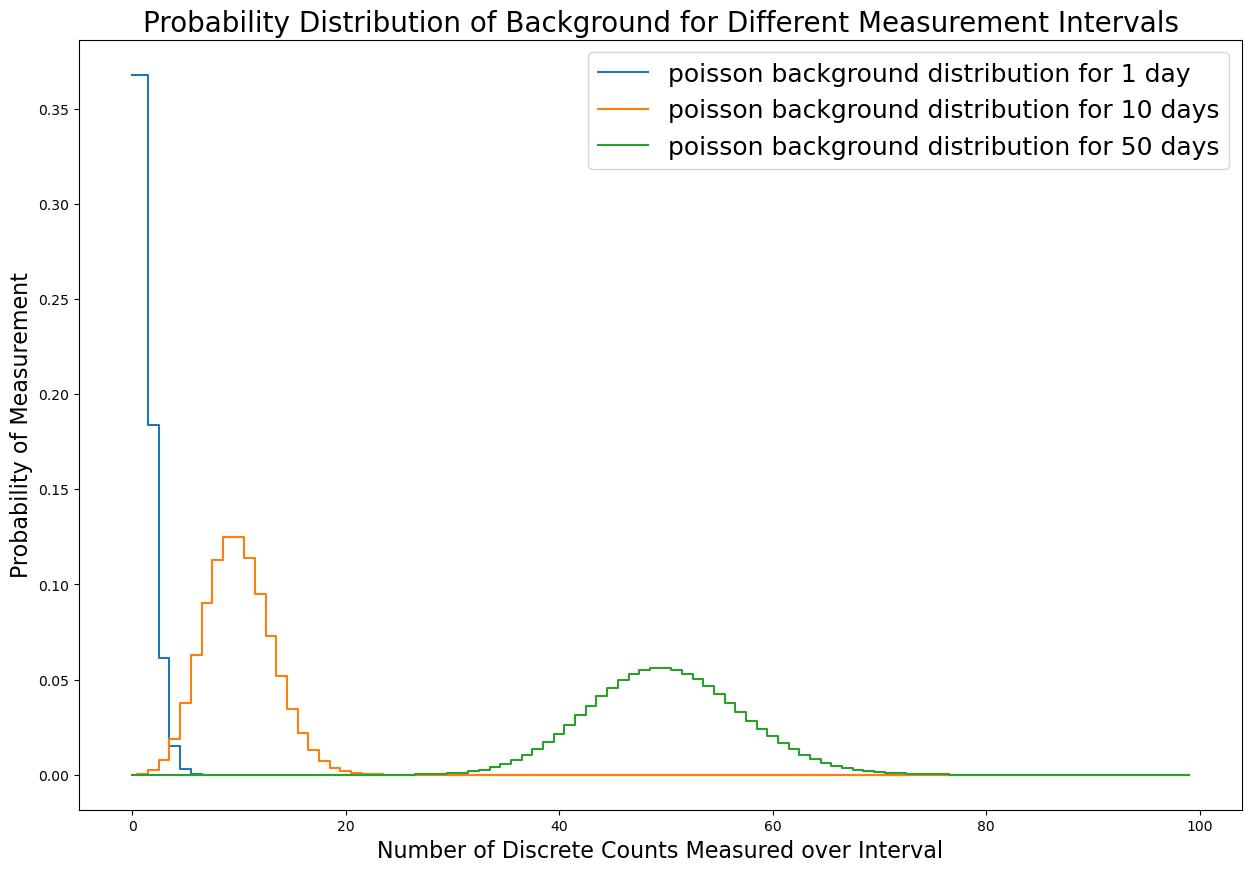

In [201]:
# A

#importing packages
import scipy as sp
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats
import scipy.integrate as integrate
import math

plt.rcParams["figure.figsize"] = (15,10)

X = 1 # average cosmic-ray background per day
Y = 3 # average gamma-rays by source (per day?)

# counts is simply the range of measurable events plotted on the x axis, t is the number of days
counts = np.arange(0, 100)

# one day probability distribution of background 
t = 1
mu = X * t # mu is plugged into the poisson point mass function

prob_count = stats.poisson.pmf(counts, mu)

# plotting using steps
fig, ax = plt.subplots(1, 1)
plt.step(counts, prob_count, label = "poisson background distribution for 1 day", where='mid')


# 10 days
t = 10
mu = X * t

prob_count = stats.poisson.pmf(counts, mu)
plt.step(counts, prob_count, label = "poisson background distribution for 10 days", where='mid')

# 50 days
t = 50
mu = X * t

prob_count = stats.poisson.pmf(counts, mu)

plt.step(counts, prob_count, label = "poisson background distribution for 50 days", where='mid')
plt.legend(fontsize=18)
plt.xlabel("Number of Discrete Counts Measured over Interval", fontsize=16)
plt.ylabel("Probability of Measurement", fontsize=16)
plt.title("Probability Distribution of Background for Different Measurement Intervals", fontsize=20)
plt.show()

#### B) Show that after 5 days, the summed probability distribution is still a Poisson distribution. Explain why this makes sense from a mathematical and conceptual point of view.

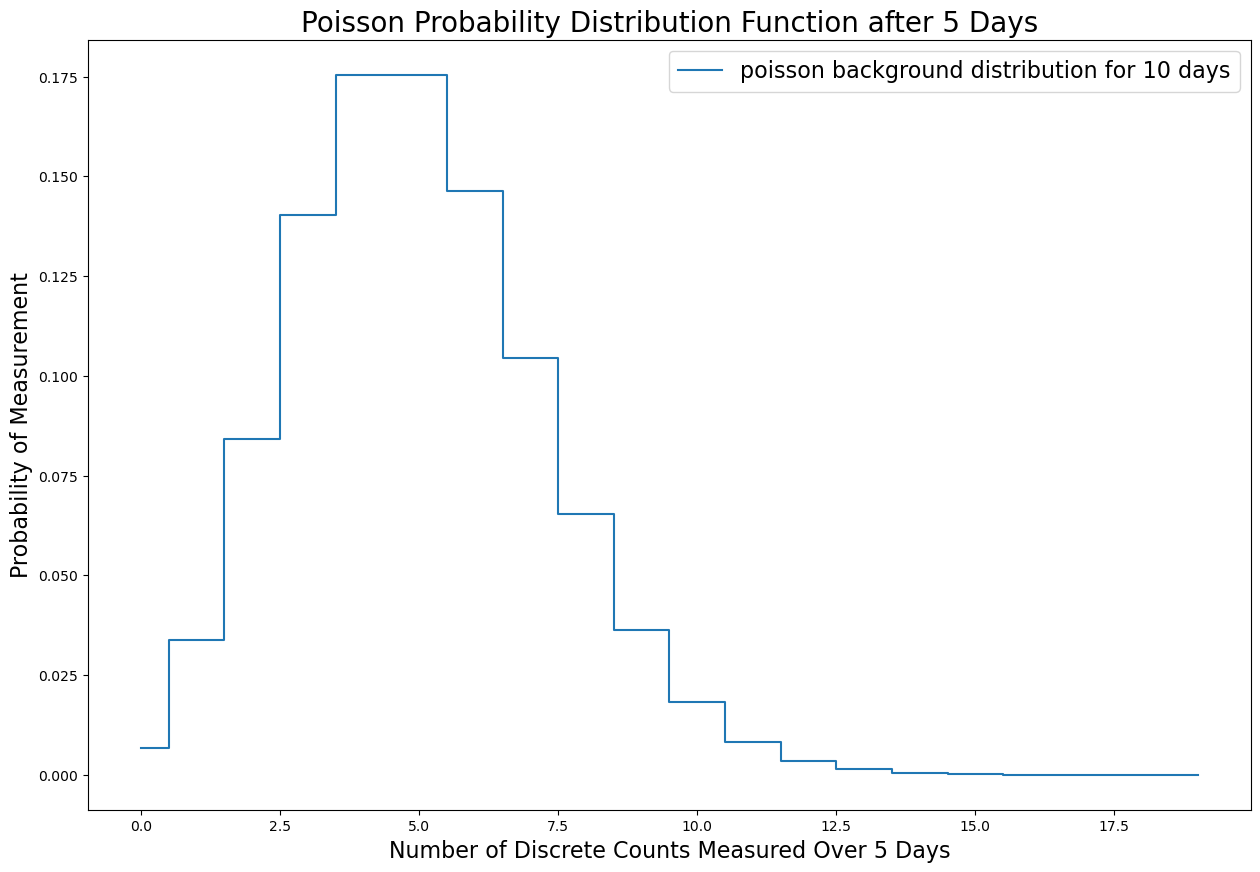

In [202]:
# B

plt.rcParams["figure.figsize"] = (15,10)

X = 1 # average cosmic-ray background per day
Y = 3 # average gamma-rays by source (per day?)

counts = np.arange(0, 20)

t = 5
mu = X * t

# prob_count = stats.poisson.pmf(k, mu)
prob_count = stats.poisson.pmf(counts, mu)

fig, ax = plt.subplots(1, 1)
plt.step(counts, prob_count, label = "poisson background distribution for 10 days", where='mid')

plt.legend(fontsize=16)
plt.xlabel("Number of Discrete Counts Measured Over 5 Days", fontsize=16)
plt.ylabel("Probability of Measurement", fontsize=16)
plt.title("Poisson Probability Distribution Function after 5 Days", fontsize=20)

plt.show()


This is still a Poisson distribution. The probability distribution of counts measured for a single day is represented with a Poisson distribution:

$$P(X = k) = \frac{\mu^k e^{-\mu}}{k!}$$

Where k is the number of counts measured, P(X = k) is the associated probability to measure k counts, and $\mu$ is the average number of counts per day. 

Now if we consider an additional day, then we need to take a convolution of two Poisson distributions. This turns out to equal a Poisson distribution with a new $\mu$ that is simply the addition of the two average number of counts per day. We can do this for all 5 days to get a new Poisson distribution that describes the probability distribution function. 

This makes sense because when we consider the variable Z = X_1 + X_2 where Z equals the sum of two random variables pulled from poisson distributions, each X variable is defined by a process with a mean average rate of producing a certain value. Adding X_1 and X_2 together is just like considering a different process where the mean average rate of producing a value is simply the sum of the X_1 mean average rate of producing a value and the same rate for X_2. And this would apply for a sum of 5 random variables, so the overall probability distribution function considering the addition of 5 of these variables (in our specific case this corresponds to 5 days of measurement) is still a Poisson distribution. 


####  C) Show how the probability distribution evolves as you average days. Calculate for many different ranges of days, and explore the shape of the distribution as the number of days becomes larger. Discuss this in relation to both B) and the central limit theoem.

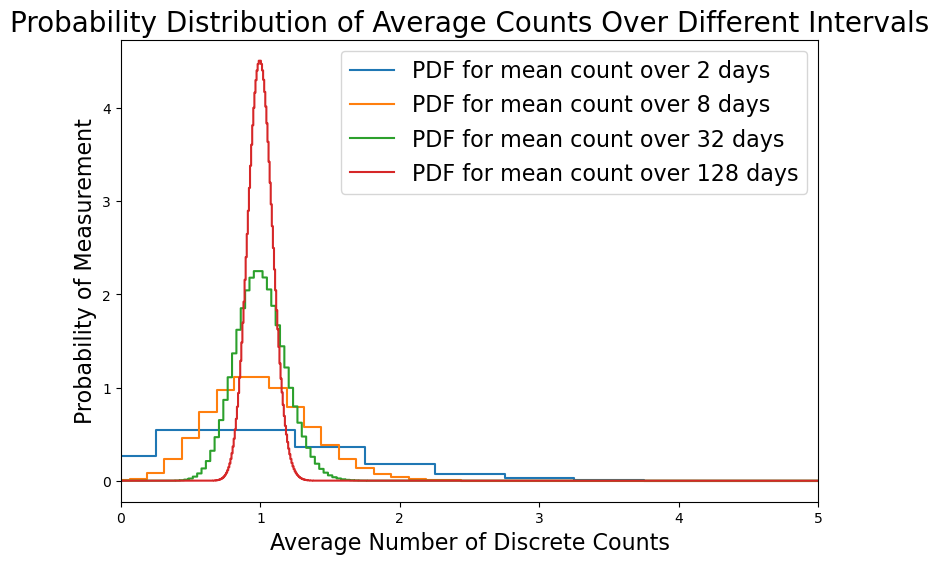

In [203]:
# C

X = 1 # average cosmic-ray background per day

intervals = [2, 8, 32, 128]

fig, ax = plt.subplots(figsize = (9,6))

for t in intervals:
    mu = X * t
    counts = np.arange(0,20 * t)
    prob_count = stats.poisson.pmf(counts, mu) * t
    counts_reduced = counts / t
    plt.step(counts_reduced, prob_count, label = f"PDF for mean count over {t} days", where='mid')

plt.title("Probability Distribution of Average Counts Over Different Intervals", fontsize=20)

plt.xlabel("Average Number of Discrete Counts", fontsize=16)
ax.set_xlim(0, 5.0)
plt.ylabel("Probability of Measurement", fontsize=16)
plt.legend(fontsize=16)

plt.show()

As the number of days we average over increases, the shape of the distribution becomes very gaussian. Comparing to part (B), it is noticed that as the gaussian forms, it appears to sharpen around the value of 1 count whereas in (B) the distribution was centered around 5 counts, which makes sense as if the mean of the original Poisson distribution is one, then we would expect a value close to 5 to be the average when considering the sum of the Poisson distributed random variables as we count over 5 days. Second, it is clear that when we average over many days, the shape approaches a gaussian shape much like we would expect according to the central limit theorem.

D) Pick some number of days N, and assume you saw Y*N gamma rays from your source. Calculate the 'sigma' of your observation. [In reality the number of gamma-rays seen from a source will also fluctuate, but we're going to ignore that complication for a couple of labs.]

In [204]:
# D

N = 10 # number of days
Y = 3
X = 1

num_rays = Y * N # number of gamma rays from source

mu = X * N

prob_count = stats.poisson.cdf(num_rays, mu) # probability that the number of counts was less than num_rays

sigma = stats.norm.ppf(prob_count, loc=0, scale=1) # converting to sigma using normal distribution
print(f"The associated sigma is: {sigma}")





The associated sigma is: 5.241037921919055


## Problem 2

Pick a skewed continuous distribtuion, such as a Rayleigh, that describes your background over some observing interval.

A) Show how the distribution changes as you average over more observing intervals.

B) Discuss how the shape changes. Does it approach a Gaussian distribution? If yes, after how many intervals?

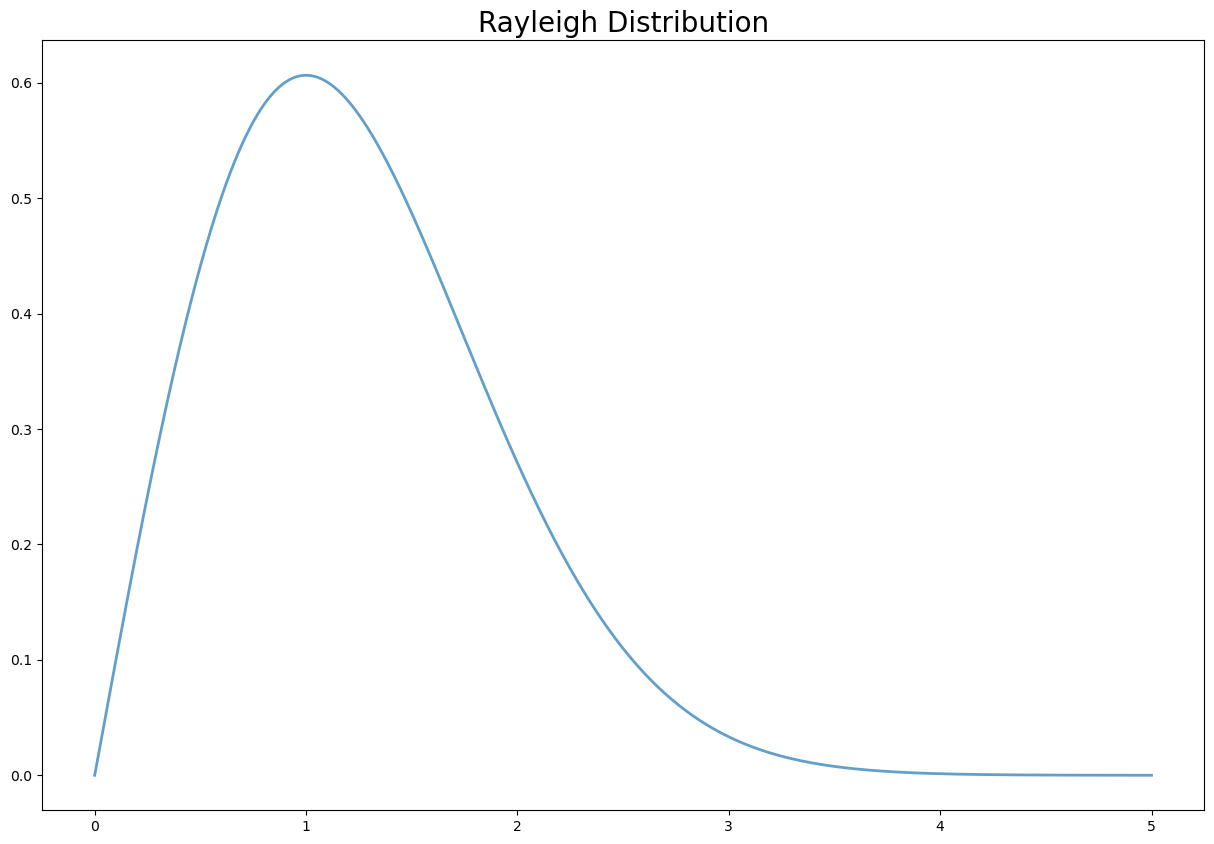

In [205]:
# prob_count = stats.poisson.pmf(k, mu)
fig, ax = plt.subplots(1, 1)
x = np.linspace(0,5,1000)
# this is the probability density function
ax.plot(x,stats.rayleigh.pdf(x,loc = 0.0, scale = 1),linewidth = 2,alpha = 0.7)

plt.title("Rayleigh Distribution", fontsize = 20)
plt.show()

A) Show how the distribution changes as you average over more observing intervals.

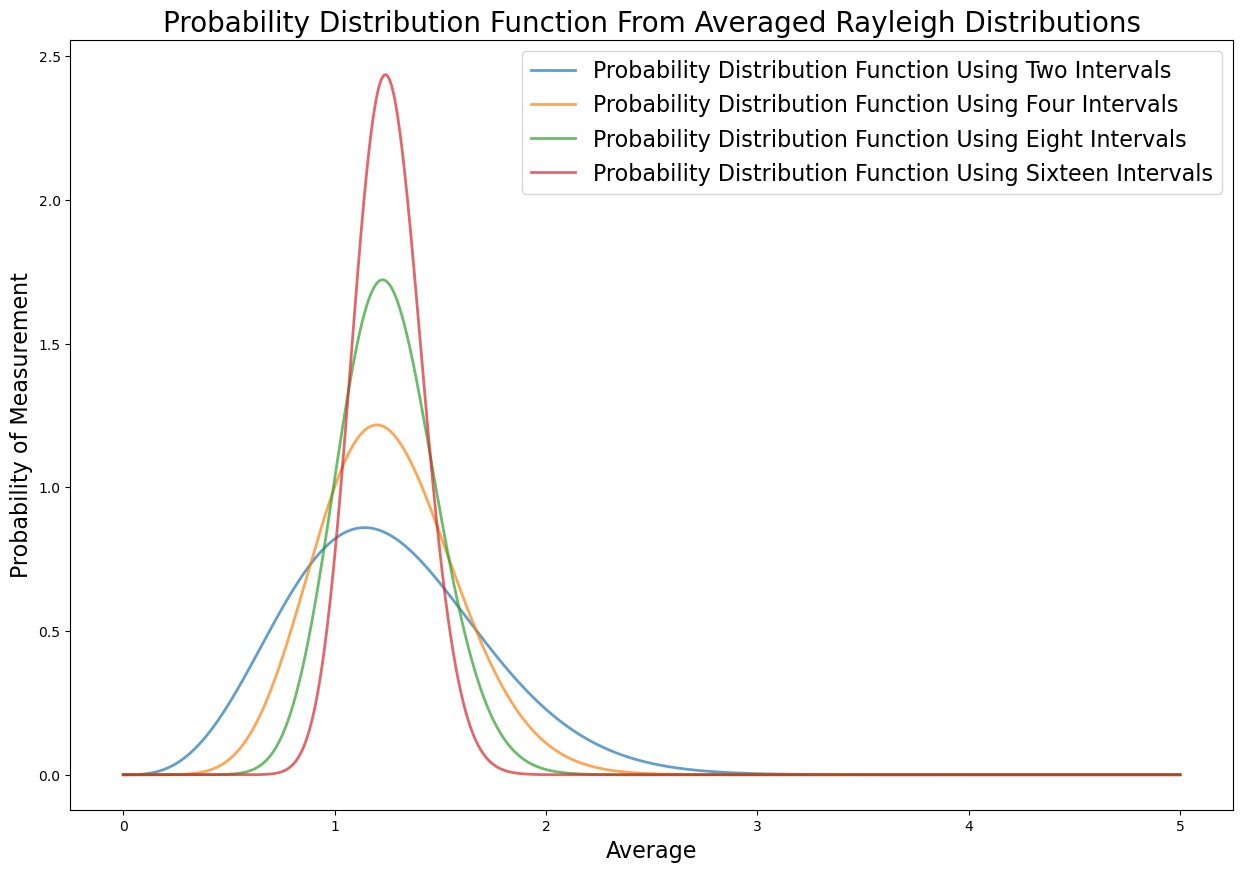

In [212]:
fig, ax = plt.subplots(1, 1)

intervals = [2, 4, 8]

x = np.linspace(0, 5, 4000) # plotting from 0 to 5 with 4000 points

dx = x[1] - x[0] # dx is needed to multiply against convolutions because without it the area scaling of the pdfs break down

ray_pdf = stats.rayleigh.pdf(x,loc = 0.0, scale = 1)

# convolving to get average of two intervals
conv_pdf_2 = np.convolve(ray_pdf, ray_pdf, mode='full') * dx
conv_pdf_4 = np.convolve(conv_pdf_2, conv_pdf_2, mode='full') * dx
conv_pdf_8 = np.convolve(conv_pdf_4, conv_pdf_4, mode='full') * dx
conv_pdf_16 = np.convolve(conv_pdf_8, conv_pdf_8, mode='full') * dx

conv_pdf_2 = conv_pdf_2 * 2
conv_pdf_4 = conv_pdf_4 * 4
conv_pdf_8 = conv_pdf_8 * 8
conv_pdf_16 = conv_pdf_16 * 16

y_2 = np.linspace(0, 10, len(conv_pdf_2))
y_4 = np.linspace(0, 20, len(conv_pdf_4))
y_8 = np.linspace(0, 40, len(conv_pdf_8))
y_16 = np.linspace(0, 80, len(conv_pdf_16))

y_2 = y_2 / 2
y_4 = y_4 / 4
y_8 = y_8 / 8
y_16 = y_16 / 16

# plotting
ax.plot(y_2,conv_pdf_2, label = "Probability Distribution Function Using Two Intervals", linewidth = 2,alpha = 0.7)
ax.plot(y_4,conv_pdf_4, label = "Probability Distribution Function Using Four Intervals", linewidth = 2,alpha = 0.7)
ax.plot(y_8,conv_pdf_8, label = "Probability Distribution Function Using Eight Intervals", linewidth = 2,alpha = 0.7)
ax.plot(y_16,conv_pdf_16, label = "Probability Distribution Function Using Sixteen Intervals", linewidth = 2,alpha = 0.7)

plt.title("Probability Distribution Function From Averaged Rayleigh Distributions", fontsize=20)
plt.xlabel("Average", fontsize=16)
plt.ylabel("Probability of Measurement", fontsize=16)
plt.legend(fontsize=16)

plt.show()


B) Discuss how the shape changes. Does it approach a Gaussian distribution? If yes, after how many intervals?

Answer: It does approach a Gaussian distribution. It is skewed to the left and as the number of intervals increases the skew decreases and the distributions get more centered on what I expect to be the mean. The distribution for two intervals isn't very Gaussian, but the one four four intervals starts looking Gaussian and by sixteen intervals the shape is very Gaussian.

## Problem 3

The discovery of optical/infra-red counterparts of Neutron star mergers initially detected with gravity-waves is one of the great discoverys in the last few years (wikipedia, scientific paper), and has ushered in the age of "multi-messenger astrophysics." The science that can be done by matching a gravity-wave signal (directly measures the mass of the neutron stars and their distance) with the optical emisson (redshift, nuclear astrophysics of the resulting explosion) is staggering. Lots of science from how the heaviest elements are formed to constraints on Dark Energy.

We're going to explore one of the analysis questions that comes up when looking for the optical counterparts (a new optical source) of a gravity wave signal. For this problem let's assume that we are using an optical telescope with a thermal noise background from the CCD (dark current, particularly an issue with older CCDs and/or infra-red CCDs). After flat-fielding, the background appears as a zero-mean Gaussian with constant width over the image.

### Version 1

You have an alert from LIGO that is also seen in with the X-ray/ultra-violet satellite SWIFT. SWIFT gives you a very precise location, so you take an image of that part of the sky. But because of SWIFT's accuracy, you know which pixel in your image to look for a counterpart in.

A) From looking at all the other pixels in your image, you can measure the width of the background Gaussian distribution X (pick something). Assuming you see a signal of strength Y (pick a floating-point number; typical optical CCDs are not sensitive enough to count photons so the readings are floating point brightnesses, not integer photons). Calculate the significance of your detection. Can you claim a discovery (traditionally 5-sigma or more)?

In [213]:
width_X = 4.0
Y = 20.0

# X = stats.norm.pdf(x, loc=0, scale = width_X) pdf of background for reference

X_cdf = stats.norm.sf(Y, loc = 0, scale = width_X)
sigma = stats.norm.isf(X_cdf, loc=0, scale=1)

print(f"sigma value is {sigma}")
print("We would declare a discovery.")


sigma value is 5.000000000000001
We would declare a discovery.


## Version 2

You have an alert from LIGO, but no associated detection from SWIFT. This could be because it is a black hole-black hole merger, a black hole-neutron star merger (neither seem to emit X-rays or UV light), or it could because SWIFT was indisposed at the time (wrong side of the earth in its orbit). Whatever the cause, you know what region of the sky to look in, but not which pixel.

B) If you have to look for a signal in 10k pixels, what is the probability distribution of your background? (Clearly state the statistical question, then turn that into math using your background distribution from part 1 of this problem.)

C) Taking your brightest candidate signal from the region (assume it has the same signal as in part 1), calculate the significance of your detection.

#### Answer to B:
The question we will ask: What is the probability that any one or more of the pixels has a measurement that is signal like?

In [214]:
# Prob distr. func. for B

X_cdf = stats.norm.sf(Y, loc=0, scale=width_X) * 10000 # we multiply by the number of sensors
sigma = stats.norm.isf(X_cdf, loc=0, scale=1)

print(f"sigma value is {sigma}")
print("We would not declare a discovery as sigma is less than 5.0 unlike before.")



sigma value is 2.7626721829080356
We would not declare a discovery as sigma is less than 5.0 unlike before.


## Problem 4

The statistical issue we were exploring in the previous problem is called a trials factor (sometimes known as a look-elsewhere effect). This is an important effect, as if you search through a million locations, you would expect to see approximately 1 one-in-a-million event. However, it is also often over estimated how big an impact this makes on the sensitivity of a search. So in this part of the lab we are going to invert the problem.

Let us again assume we have a Gaussian background (same parameters as Problem 3).

A) Calculate the signal required for a 5-sigma detection in Version 1

B) Calculate the signal required for a 5-sigma detection in Version 2

C) Discuss how much brighter the signal must be for discoverey if you have a trials factor of 10k. Looking at your probability distributions, explain why the sensitivity penalty due to a trials factor is so low.

D) If you changed the trials factor significantly (orders of magnitude), how large is the effect on your 5-sigma sensitivity threshold?

In [215]:
width_X = 4.0
Y = 20.0

# X = stats.norm.pdf(x, loc=0, scale = width_X) pdf of background for reference

# A)
X_cdf = stats.norm.sf(20.0, loc = 0, scale = width_X)
sigma = stats.norm.isf(X_cdf, loc=0, scale=1)

print(f"In version I we need Y = 20.0 to get to sigma = {sigma:.2f}")

# B)
X_cdf = stats.norm.sf(26.2, loc = 0, scale = width_X) * 10**4
sigma = stats.norm.isf(X_cdf, loc=0, scale=1)

print(f"In version II we need Y = 26.2 to get to sigma = {sigma:.2f}")

# C) if the original signal has stength Y = 20.0 then one would need a signal strength about 30 % stronger for the same sigma
# considering the trials factor of 10k

# D) if we make the trials factor 1 million for example, then the effect on the 5-sigma threshold is to require an additional
# sigma of significance. In general, it appears for every 2 orders of magnitude increase in the trial factor, an additional
# sigma when considering measurement without a trials factor is required to stay above 5 sigma when we do consider it.



In version I we need Y = 20.0 to get to sigma = 5.00
In version II we need Y = 26.2 to get to sigma = 5.00
